In [1]:
import pandas as pd

# 指定Excel文件路径
excel_file_path = 'data/数据集成与处理/20250519zwj数据爬取/微博帖子（gbk）.xlsx'  # 替换为你的Excel文件路径

# 使用pandas读取Excel文件
# 假设你的Excel文件只有一个工作表，如果有多个工作表，可以指定sheet_name参数
df = pd.read_excel(excel_file_path)

# 指定要保存的TXT文件路径
txt_file_path = 'data/情感分析文本数据'  # 输出的TXT文件名

# 将DataFrame转换为字符串，并保存为UTF-8编码的TXT文件
with open(txt_file_path, 'w', encoding='utf-8') as txt_file:
    txt_file.write(df.to_string(index=False))

print(f"数据已成功保存到 {txt_file_path} 文件中，编码格式为UTF-8。")


数据已成功保存到 /Users/xiehongtan/Desktop/情感分析文本数据 文件中，编码格式为UTF-8。


2025-05-25 12:46:48,076 - INFO - 成功读取文件: /Users/xiehongtan/Desktop/情感分析文本数据
2025-05-25 12:46:56,454 - INFO - 情感分析完成
2025-05-25 12:46:56,456 - INFO - 积极情感系数: 0.952413963918621
2025-05-25 12:46:56,457 - INFO - 消极情感系数: 0.036402629356888774
2025-05-25 12:46:56,457 - INFO - 中性情感系数: 0.5133195103541653


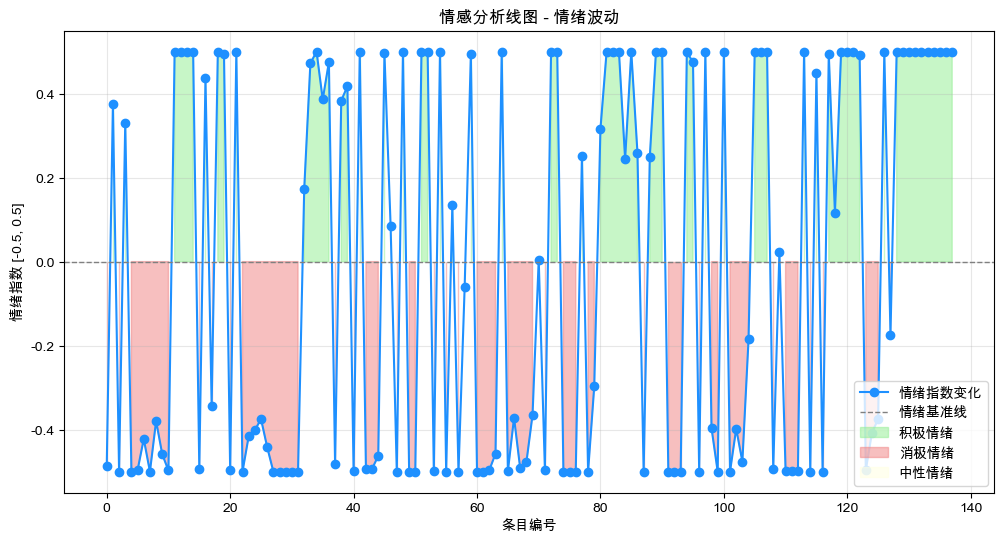

2025-05-25 12:46:57,667 - INFO - 情感波动折线图已保存到: ./output/情感分析线图-丰富版.png


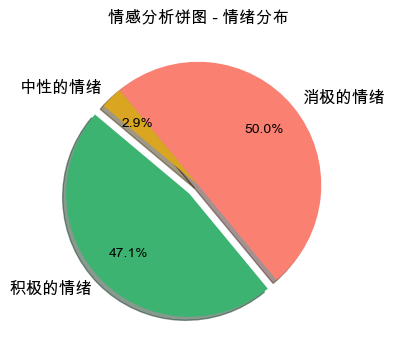

2025-05-25 12:46:57,816 - INFO - 情感分布饼图已保存到: ./output/情感分析饼图-丰富版.png


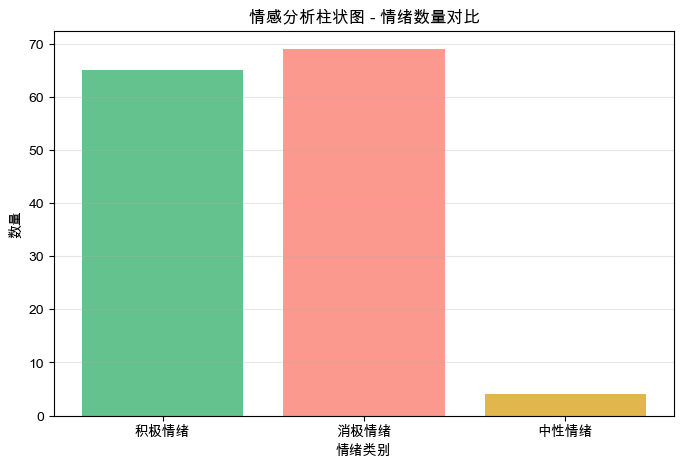

2025-05-25 12:46:58,039 - INFO - 情感数量柱状图已保存到: ./output/情感分析柱状图.png


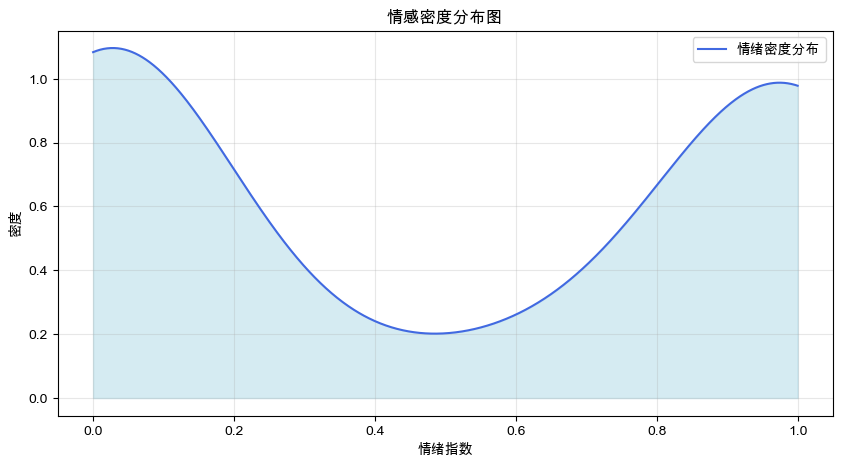

2025-05-25 12:47:21,937 - INFO - 情感密度分布图已保存到: ./output/情感密度分布图.png


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from snownlp import SnowNLP
import random
import logging
import os

# 配置日志
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

# 配置文件路径和图表保存路径
CONFIG = {
    'file_path': 'data/情感分析文本数据',
    'output_dir': './output',
    'font': 'Arial Unicode MS',  # macOS, 用来正常显示中文标签
    'sentiment_thresholds': {'positive': 0.6, 'negative': 0.4, 'neutral': 0.4}
}

# 确保输出目录存在
os.makedirs(CONFIG['output_dir'], exist_ok=True)

def read_text_file(file_path):
    """读取文本文件"""
    try:
        with open(file_path, 'r', encoding='utf-8') as file:
            lines = file.readlines()
            lines = [line.strip() for line in lines if line.strip()]  # 移除空白行
        logging.info(f"成功读取文件: {file_path}")
        return lines
    except FileNotFoundError:
        logging.error(f"文件未找到: {file_path}")
        return []
    except Exception as e:
        logging.error(f"读取文件时出错: {e}")
        return []

def analyze_sentiments(source):
    """分析文本情感"""
    sentimentslist = []
    for content in source:
        try:
            s = SnowNLP(content)
            sentimentslist.append(s.sentiments)
        except Exception as e:
            logging.warning(f"情感分析失败: {content} - {e}")
    logging.info("情感分析完成")
    return sentimentslist

def plot_sentiment_line_chart(results, output_path):
    """绘制情感波动折线图"""
    if len(results) > 1000:
        results = random.sample(results, 500)
    plt.figure(figsize=(12, 6))
    plt.plot(np.arange(len(results)), results, marker='o', color='dodgerblue', label='情绪指数变化')
    plt.axhline(y=0, color='gray', linestyle='--', linewidth=1, label='情绪基准线')
    plt.fill_between(np.arange(len(results)), results, 0, where=(np.array(results) > 0.1), color='lightgreen', alpha=0.5, label='积极情绪')
    plt.fill_between(np.arange(len(results)), results, 0, where=(np.array(results) < -0.1), color='lightcoral', alpha=0.5, label='消极情绪')
    plt.fill_between(np.arange(len(results)), results, 0, where=(np.abs(np.array(results)) <= 0.1), color='lightyellow', alpha=0.5, label='中性情绪')
    plt.xlabel('条目编号')
    plt.ylabel('情绪指数 [-0.5, 0.5]')
    plt.title('情感分析线图 - 情绪波动')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.savefig(output_path)
    plt.show()
    logging.info(f"情感波动折线图已保存到: {output_path}")

def plot_sentiment_pie_chart(positive_count, negative_count, neutral_count, output_path):
    """绘制情感分布饼图"""
    labels = ['积极的情绪', '消极的情绪', '中性的情绪']
    sizes = [positive_count, negative_count, neutral_count]
    colors = ['mediumseagreen', 'salmon', 'goldenrod']
    explode = (0.1, 0, 0)  # 突出显示积极情绪部分

    plt.figure(figsize=(8, 4))
    wedges, texts, autotexts = plt.pie(
        sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%',
        shadow=True, startangle=140, textprops={'fontsize': 12}, pctdistance=0.7
    )
    plt.setp(autotexts, size=10, weight='bold', color='black')
    plt.title('情感分析饼图 - 情绪分布')
    plt.savefig(output_path)
    plt.show()
    logging.info(f"情感分布饼图已保存到: {output_path}")

def plot_bar_chart(positive_count, negative_count, neutral_count, output_path):
    """绘制情感数量柱状图"""
    categories = ['积极情绪', '消极情绪', '中性情绪']
    values = [positive_count, negative_count, neutral_count]
    colors = ['mediumseagreen', 'salmon', 'goldenrod']

    plt.figure(figsize=(8, 5))
    plt.bar(categories, values, color=colors, alpha=0.8)
    plt.xlabel('情绪类别')
    plt.ylabel('数量')
    plt.title('情感分析柱状图 - 情绪数量对比')
    plt.grid(axis='y', alpha=0.3)
    plt.savefig(output_path)
    plt.show()
    logging.info(f"情感数量柱状图已保存到: {output_path}")

def plot_density_chart(sentimentslist, output_path):
    """绘制情感密度分布图"""
    from scipy.stats import gaussian_kde

    density = gaussian_kde(sentimentslist)
    x = np.linspace(0, 1, 1000)
    y = density(x)

    plt.figure(figsize=(10, 5))
    plt.plot(x, y, color='royalblue', label='情绪密度分布')
    plt.fill_between(x, y, color='lightblue', alpha=0.5)
    plt.xlabel('情绪指数')
    plt.ylabel('密度')
    plt.title('情感密度分布图')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.savefig(output_path)
    plt.show()
    logging.info(f"情感密度分布图已保存到: {output_path}")

def main(config):
    """主函数"""
    # 设置 Matplotlib 的字体和负号显示
    plt.rcParams['font.sans-serif'] = [config['font']]  # macOS, 用来正常显示中文标签
    plt.rcParams['axes.unicode_minus'] = False  # 用来正常显示负号

    # 读取文件
    source = read_text_file(config['file_path'])
    if not source:
        logging.error("未读取到有效数据，程序终止")
        return

    # 分析情感
    sentimentslist = analyze_sentiments(source)

    # 计算正向、反向和中性情感系数
    positive_sentiments = [x for x in sentimentslist if x > config['sentiment_thresholds']['positive']]
    negative_sentiments = [x for x in sentimentslist if x < config['sentiment_thresholds']['negative']]
    neutral_sentiments = [x for x in sentimentslist if config['sentiment_thresholds']['neutral'] <= x <= config['sentiment_thresholds']['positive']]

    positive_coefficient = np.mean(positive_sentiments) if positive_sentiments else 0
    negative_coefficient = np.mean(negative_sentiments) if negative_sentiments else 0
    neutral_coefficient = np.mean(neutral_sentiments) if neutral_sentiments else 0

    logging.info(f"积极情感系数: {positive_coefficient}")
    logging.info(f"消极情感系数: {negative_coefficient}")
    logging.info(f"中性情感系数: {neutral_coefficient}")

    # 区间转换为[-0.5, 0.5]
    results = [x - 0.5 for x in sentimentslist]

    # 绘制各种图表
    plot_sentiment_line_chart(results, os.path.join(config['output_dir'], '情感分析线图-丰富版.png'))
    plot_sentiment_pie_chart(len(positive_sentiments), len(negative_sentiments), len(neutral_sentiments), os.path.join(config['output_dir'], '情感分析饼图-丰富版.png'))
    plot_bar_chart(len(positive_sentiments), len(negative_sentiments), len(neutral_sentiments), os.path.join(config['output_dir'], '情感分析柱状图.png'))
    plot_density_chart(sentimentslist, os.path.join(config['output_dir'], '情感密度分布图.png'))

if __name__ == '__main__':
    main(CONFIG)


2025-05-25 13:25:13,339 - INFO - 成功读取文件: /Users/xiehongtan/Desktop/情感分析文本数据
2025-05-25 13:25:21,765 - INFO - 情感分析完成


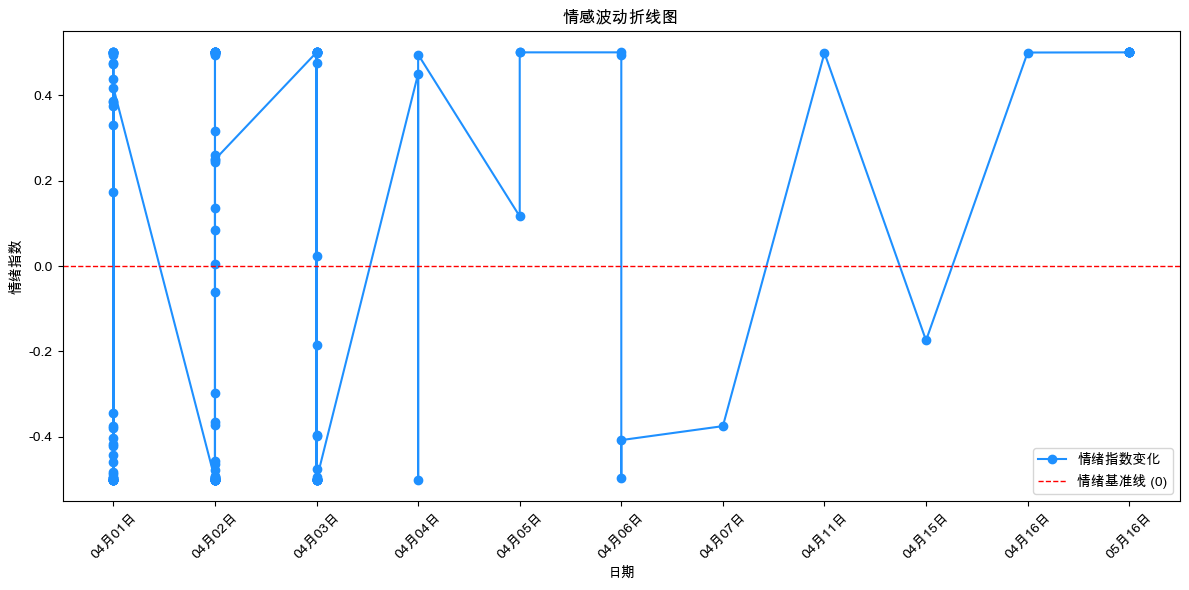

2025-05-25 13:25:22,199 - INFO - 情感波动折线图已保存到: ./output/情感波动折线图.png


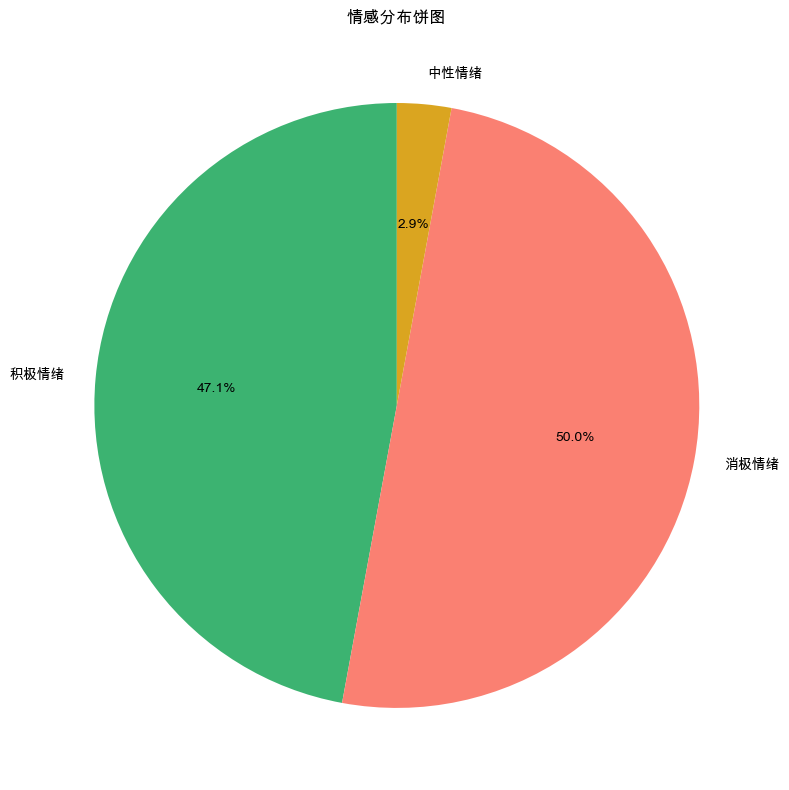

2025-05-25 13:25:22,421 - INFO - 情感分布饼图已保存到: ./output/情感分布饼图.png


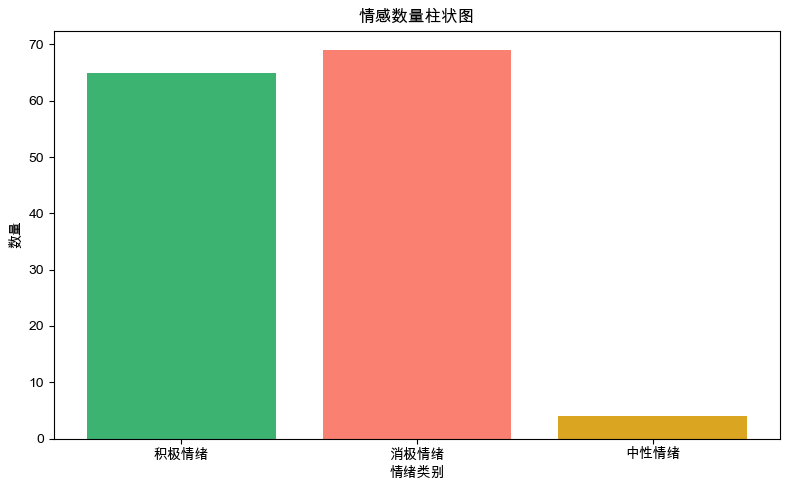

2025-05-25 13:25:22,674 - INFO - 情感数量柱状图已保存到: ./output/情感数量柱状图.png


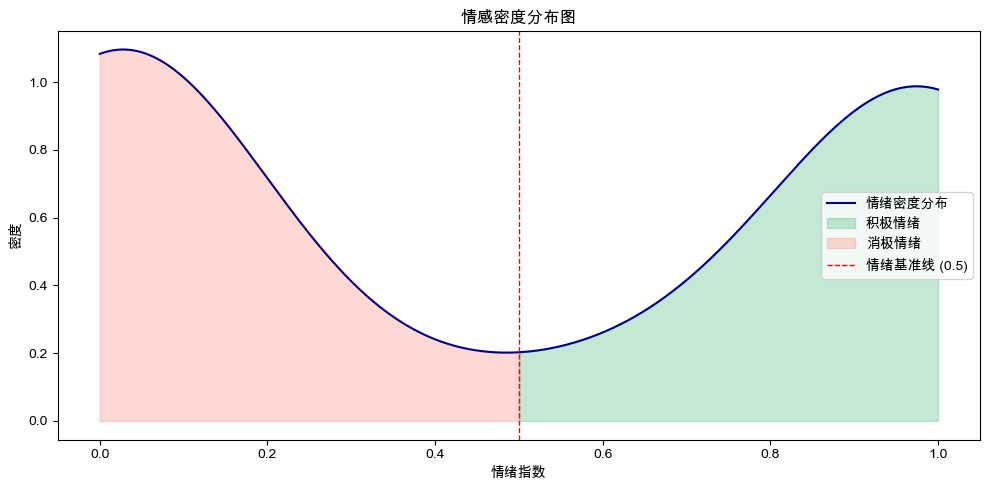

2025-05-25 13:25:23,238 - INFO - 情感密度分布图已保存到: ./output/情感密度分布图.png


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from snownlp import SnowNLP
import random
import logging
import os
import re

# 配置日志
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

# 配置文件路径和图表保存路径
CONFIG = {
    'file_path': 'data/情感分析文本数据',
    'output_dir': './output',
    'font': 'Arial Unicode MS',  # macOS, 用来正常显示中文标签
    'sentiment_thresholds': {'positive': 0.6, 'negative': 0.4, 'neutral': 0.4}
}

# 确保输出目录存在
os.makedirs(CONFIG['output_dir'], exist_ok=True)

def read_text_file(file_path):
    """读取文本文件"""
    try:
        with open(file_path, 'r', encoding='utf-8') as file:
            lines = file.readlines()
            lines = [line.strip() for line in lines if line.strip()]  # 移除空白行
        logging.info(f"成功读取文件: {file_path}")
        return lines
    except FileNotFoundError:
        logging.error(f"文件未找到: {file_path}")
        return []
    except Exception as e:
        logging.error(f"读取文件时出错: {e}")
        return []

def analyze_sentiments(source):
    """分析文本情感"""
    sentimentslist = []
    dates = []
    for line in source:
        try:
            # 提取日期
            date_match = re.search(r'\d{2}月\d{2}日', line)
            if date_match:
                date = date_match.group()
                dates.append(date)
            else:
                dates.append('未知日期')
            
            # 提取内容
            content = re.sub(r'\d{2}月\d{2日}.*?#', '', line).strip()
            if content:
                s = SnowNLP(content)
                sentimentslist.append(s.sentiments)
        except Exception as e:
            logging.warning(f"情感分析失败: {line} - {e}")
    logging.info("情感分析完成")
    return dates, sentimentslist

def plot_sentiment_line_chart(dates, results, output_path):
    """绘制情感波动折线图"""
    if len(results) > 1000:
        results = random.sample(results, 500)
        dates = random.sample(dates, 500)
    
    plt.figure(figsize=(12, 6))
    plt.plot(dates, results, marker='o', color='dodgerblue', label='情绪指数变化')
    plt.axhline(y=0, color='red', linestyle='--', linewidth=1, label='情绪基准线 (0)')  # 添加基准线
    plt.xlabel('日期')
    plt.ylabel('情绪指数')
    plt.title('情感波动折线图')
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_path)
    plt.show()
    logging.info(f"情感波动折线图已保存到: {output_path}")

def plot_sentiment_pie_chart(positive_count, negative_count, neutral_count, output_path):
    """绘制情感分布饼图"""
    labels = ['积极情绪', '消极情绪', '中性情绪']
    sizes = [positive_count, negative_count, neutral_count]
    colors = ['mediumseagreen', 'salmon', 'goldenrod']

    plt.figure(figsize=(8, 8))
    plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
    plt.title('情感分布饼图')
    plt.axis('equal')
    plt.tight_layout()
    plt.savefig(output_path)
    plt.show()
    logging.info(f"情感分布饼图已保存到: {output_path}")

def plot_bar_chart(positive_count, negative_count, neutral_count, output_path):
    """绘制情感数量柱状图"""
    categories = ['积极情绪', '消极情绪', '中性情绪']
    values = [positive_count, negative_count, neutral_count]
    colors = ['mediumseagreen', 'salmon', 'goldenrod']

    plt.figure(figsize=(8, 5))
    plt.bar(categories, values, color=colors)
    plt.xlabel('情绪类别')
    plt.ylabel('数量')
    plt.title('情感数量柱状图')
    plt.tight_layout()
    plt.savefig(output_path)
    plt.show()
    logging.info(f"情感数量柱状图已保存到: {output_path}")

def plot_density_chart(sentimentslist, output_path):
    """绘制情感密度分布图"""
    from scipy.stats import gaussian_kde

    density = gaussian_kde(sentimentslist)
    x = np.linspace(0, 1, 1000)
    y = density(x)

    plt.figure(figsize=(10, 5))
    plt.plot(x, y, color='darkblue', label='情绪密度分布')
    plt.fill_between(x, y, where=(x > 0.5), color='mediumseagreen', alpha=0.3, label='积极情绪')
    plt.fill_between(x, y, where=(x <= 0.5), color='salmon', alpha=0.3, label='消极情绪')
    plt.axvline(x=0.5, color='red', linestyle='--', linewidth=1, label='情绪基准线 (0.5)')  # 添加基准线
    plt.xlabel('情绪指数')
    plt.ylabel('密度')
    plt.title('情感密度分布图')
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_path)
    plt.show()
    logging.info(f"情感密度分布图已保存到: {output_path}")

def main(config):
    """主函数"""
    # 设置 Matplotlib 的字体和负号显示
    plt.rcParams['font.sans-serif'] = [config['font']]  
    plt.rcParams['axes.unicode_minus'] = False  

    # 读取文件
    source = read_text_file(config['file_path'])
    if not source:
        logging.error("未读取到有效数据，程序终止")
        return

    # 分析情感
    dates, sentimentslist = analyze_sentiments(source)

    # 计算正向、反向和中性情感数量
    positive_sentiments = [x for x in sentimentslist if x > config['sentiment_thresholds']['positive']]
    negative_sentiments = [x for x in sentimentslist if x < config['sentiment_thresholds']['negative']]
    neutral_sentiments = [x for x in sentimentslist if config['sentiment_thresholds']['neutral'] <= x <= config['sentiment_thresholds']['positive']]

    # 区间转换为[-0.5, 0.5]
    results = [x - 0.5 for x in sentimentslist]

    # 绘制各种图表
    plot_sentiment_line_chart(dates, results, os.path.join(config['output_dir'], '情感波动折线图.png'))
    plot_sentiment_pie_chart(len(positive_sentiments), len(negative_sentiments), len(neutral_sentiments), os.path.join(config['output_dir'], '情感分布饼图.png'))
    plot_bar_chart(len(positive_sentiments), len(negative_sentiments), len(neutral_sentiments), os.path.join(config['output_dir'], '情感数量柱状图.png'))
    plot_density_chart(sentimentslist, os.path.join(config['output_dir'], '情感密度分布图.png'))

if __name__ == '__main__':
    main(CONFIG)
